In [1]:

!pip install -q tensorflow scikit-learn pandas numpy matplotlib


In [2]:

from google.colab import files
import os
import zipfile
import glob

uploaded = files.upload()

# Find the uploaded file
uploaded_file = list(uploaded.keys())[0]

# Extract ZIP, or use the CSV directly
if uploaded_file.lower().endswith(".zip"):
    with zipfile.ZipFile(uploaded_file, "r") as zip_ref:
        zip_ref.extractall("/content/rainfall_data")
    print("Dataset extracted successfully!")
elif uploaded_file.lower().endswith(".csv"):
    os.makedirs("/content/rainfall_data", exist_ok=True)
    os.replace(uploaded_file, "/content/rainfall_data/" + uploaded_file)
    print("CSV uploaded successfully!")
else:
    raise ValueError("Please upload the dataset ZIP or CSV file.")

# Locate CSV files
csv_files = glob.glob(
    "/content/rainfall_data/**/*.csv", recursive=True
)

print("CSV files found:", csv_files)


Saving archive (1).zip to archive (1).zip
Dataset extracted successfully!
CSV files found: ['/content/rainfall_data/Indian Rainfall Dataset District-wise Daily Measurements.csv']


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

file_path = csv_files[0]
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values in each column:")
print(df.isnull().sum())

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

file_path = csv_files[0]
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values in each column:")
print(df.isnull().sum())


Dataset loaded successfully!
Dataset shape: (8790, 1)

Column names:
['state;"district";"month";"1st";"2nd";"3rd";"4th";"5th";"6th";"7th";"8th";"9th";"10th";"11th";"12th";"13th";"14th";"15th";"16th";"17th";"18th";"19th";"20th";"21st";"22nd";"23rd";"24th";"25th";"26th";"27th";"28th";"29th";"30th";"31st"']

First 5 rows:


,"state;""district"";""month"";""1st"";""2nd"";""3rd"";""4th"";""5th"";""6th"";""7th"";""8th"";""9th"";""10th"";""11th"";""12th"";""13th"";""14th"";""15th"";""16th"";""17th"";""18th"";""19th"";""20th"";""21st"";""22nd"";""23rd"";""24th"";""25th"";""26th"";""27th"";""28th"";""29th"";""30th"";""31st"""
0,"Andaman & Nicobar;""Nicobars"";1;0.0;0.0;0.0;0.0..."
1,"Andaman & Nicobar;""North And Middle Andaman"";1..."
2,"Andaman & Nicobar;""South Andamans"";1;0.0;0.0;0..."
3,"Andhra Pradesh;""Anantapur"";1;0.379965;0.0;0.0;..."
4,"Andhra Pradesh;""Chittoor"";1;14.1449;0.857263;0..."



Missing values in each column:
state;"district";"month";"1st";"2nd";"3rd";"4th";"5th";"6th";"7th";"8th";"9th";"10th";"11th";"12th";"13th";"14th";"15th";"16th";"17th";"18th";"19th";"20th";"21st";"22nd";"23rd";"24th";"25th";"26th";"27th";"28th";"29th";"30th";"31st"    0
dtype: int64
Dataset loaded successfully!
Dataset shape: (8790, 1)

Column names:
['state;"district";"month";"1st";"2nd";"3rd";"4th";"5th";"6th";"7th";"8th";"9th";"10th";"11th";"12th";"13th";"14th";"15th";"16th";"17th";"18th";"19th";"20th";"21st";"22nd";"23rd";"24th";"25th";"26th";"27th";"28th";"29th";"30th";"31st"']

First 5 rows:


,"state;""district"";""month"";""1st"";""2nd"";""3rd"";""4th"";""5th"";""6th"";""7th"";""8th"";""9th"";""10th"";""11th"";""12th"";""13th"";""14th"";""15th"";""16th"";""17th"";""18th"";""19th"";""20th"";""21st"";""22nd"";""23rd"";""24th"";""25th"";""26th"";""27th"";""28th"";""29th"";""30th"";""31st"""
0,"Andaman & Nicobar;""Nicobars"";1;0.0;0.0;0.0;0.0..."
1,"Andaman & Nicobar;""North And Middle Andaman"";1..."
2,"Andaman & Nicobar;""South Andamans"";1;0.0;0.0;0..."
3,"Andhra Pradesh;""Anantapur"";1;0.379965;0.0;0.0;..."
4,"Andhra Pradesh;""Chittoor"";1;14.1449;0.857263;0..."



Missing values in each column:
state;"district";"month";"1st";"2nd";"3rd";"4th";"5th";"6th";"7th";"8th";"9th";"10th";"11th";"12th";"13th";"14th";"15th";"16th";"17th";"18th";"19th";"20th";"21st";"22nd";"23rd";"24th";"25th";"26th";"27th";"28th";"29th";"30th";"31st"    0
dtype: int64


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Read the CSV using the correct semicolon separator
file_path = csv_files[0]
df = pd.read_csv(file_path, sep=";")

# Clean column names
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace('"', '', regex=False)
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (8790, 34)

Column names:
['state', 'district', 'month', '1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th', '9th', '10th', '11th', '12th', '13th', '14th', '15th', '16th', '17th', '18th', '19th', '20th', '21st', '22nd', '23rd', '24th', '25th', '26th', '27th', '28th', '29th', '30th', '31st']

First 5 rows:


,state,district,month,1st,2nd,3rd,4th,5th,6th,7th,...,22nd,23rd,24th,25th,26th,27th,28th,29th,30th,31st
0,Andaman & Nicobar,Nicobars,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,Andaman & Nicobar,North And Middle Andaman,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,Andaman & Nicobar,South Andamans,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,Andhra Pradesh,Anantapur,1,0.379965,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.205834,0.671002,0.028994,0.0,0.0,0.0
4,Andhra Pradesh,Chittoor,1,14.144900,0.857263,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.615237,0.925098,0.507623,0.424843,0.737394,0.0,0.0,0.0



Missing values:
state       0
district    0
month       0
1st         0
2nd         0
3rd         0
4th         0
5th         0
6th         0
7th         0
8th         0
9th         0
10th        0
11th        0
12th        0
13th        0
14th        0
15th        0
16th        0
17th        0
18th        0
19th        0
20th        0
21st        0
22nd        0
23rd        0
24th        0
25th        0
26th        0
27th        0
28th        0
29th        0
30th        0
31st        0
dtype: int64
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [5]:

# Select Erode if available; otherwise use the first district
district_names = df["district"].dropna().astype(str).str.strip().unique()

if any(d.lower() == "erode" for d in district_names):
    selected_district = next(
        d for d in district_names if d.lower() == "erode"
    )
else:
    selected_district = district_names[0]

district_df = df[
    df["district"].astype(str).str.strip().str.lower()
    == selected_district.lower()
].copy()

print("Selected district:", selected_district)
print("Monthly rows:", len(district_df))

# Convert daily columns to long format
day_columns = [
    c for c in df.columns
    if c not in ["state", "district", "month"]
]

daily_df = district_df.melt(
    id_vars=["state", "district", "month"],
    value_vars=day_columns,
    var_name="day",
    value_name="rainfall"
)

# Extract day number: 1st -> 1, 2nd -> 2, etc.
daily_df["day"] = (
    daily_df["day"].str.extract(r"(\d+)").astype(int)
)

daily_df["month"] = pd.to_numeric(
    daily_df["month"], errors="coerce"
)
daily_df["rainfall"] = pd.to_numeric(
    daily_df["rainfall"], errors="coerce"
)

# Create dates for 2022; invalid dates such as February 30 are removed
daily_df["date"] = pd.to_datetime(
    {
        "year": 2022,
        "month": daily_df["month"],
        "day": daily_df["day"]
    },
    errors="coerce"
)

daily_df = daily_df.dropna(subset=["date"])
daily_df = daily_df.sort_values("date")
daily_df = daily_df.drop_duplicates("date", keep="last")

# One continuous row per calendar day
daily_df = (
    daily_df.set_index("date")[["rainfall"]]
    .reindex(pd.date_range("2022-01-01", "2022-12-31", freq="D"))
)
daily_df.index.name = "date"

# Fill missing measurements conservatively
daily_df["rainfall"] = daily_df["rainfall"].interpolate(
    method="time", limit_area="inside"
)
daily_df["rainfall"] = daily_df["rainfall"].fillna(0)
daily_df["rainfall"] = daily_df["rainfall"].clip(lower=0)

print("Daily dataset shape:", daily_df.shape)
print("Missing values:", daily_df["rainfall"].isna().sum())
display(daily_df.head(10))


Selected district: Erode
Monthly rows: 12
Daily dataset shape: (365, 1)
Missing values: 0


,rainfall
date,
2022-01-01,1.570880
2022-01-02,7.474100
2022-01-03,0.007245
2022-01-04,0.000000
2022-01-05,0.000000
2022-01-06,0.000000
2022-01-07,0.003344
2022-01-08,0.039571
2022-01-09,0.000000


In [6]:

# Create sequences using the previous 7 days
def create_sequences(data, window_size=7):
    X, y = [], []

    for i in range(window_size, len(data)):
        X.append(data[i-window_size:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

X_all, y_all = create_sequences(scaled_rainfall, 7)

# Date corresponding to each target value
target_dates = daily_df.index[7:]

# Split chronologically: targets before the boundary are training
train_mask = target_dates < daily_df.index[split_index]

X_train = X_all[train_mask]
y_train = y_all[train_mask]

X_test = X_all[~train_mask]
y_test = y_all[~train_mask]

# LSTM expects: samples, time steps, features
X_train = X_train.reshape(-1, 7, 1)
X_test = X_test.reshape(-1, 7, 1)

test_dates = target_dates[~train_mask]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


NameError: name 'scaled_rainfall' is not defined

In [7]:

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Get rainfall values from the daily dataset
rainfall = daily_df["rainfall"].values.reshape(-1, 1)

# Split chronologically: 80% training, 20% testing
split_index = int(len(rainfall) * 0.80)

# Normalize using only the training period
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(rainfall[:split_index])

scaled_rainfall = scaler.transform(rainfall)

print("Normalization completed successfully!")
print("Total days:", len(rainfall))
print("Training boundary:", split_index)
print("Scaled data shape:", scaled_rainfall.shape)


Normalization completed successfully!
Total days: 365
Training boundary: 292
Scaled data shape: (365, 1)


In [8]:

# Step 9: Create input-output sequences

import numpy as np

def create_sequences(data, window_size=7):
    X, y = [], []

    for i in range(window_size, len(data)):
        X.append(data[i-window_size:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

# Create sequences using the previous 7 days
X_all, y_all = create_sequences(scaled_rainfall, window_size=7)

# Get the target dates
target_dates = daily_df.index[7:]

# Separate training and testing data
train_mask = target_dates < daily_df.index[split_index]

X_train = X_all[train_mask]
y_train = y_all[train_mask]

X_test = X_all[~train_mask]
y_test = y_all[~train_mask]

# Reshape data for the LSTM model
X_train = X_train.reshape(-1, 7, 1)
X_test = X_test.reshape(-1, 7, 1)

test_dates = target_dates[~train_mask]

print("Sequence creation completed!")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


Sequence creation completed!
X_train shape: (285, 7, 1)
y_train shape: (285,)
X_test shape: (73, 7, 1)
y_test shape: (73,)


In [9]:

# Step 10: Build the LSTM model

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense

# Set random seed for reproducible results
tf.keras.utils.set_random_seed(42)

# Build the model
model = Sequential([
    Input(shape=(7, 1)),
    LSTM(50),
    Dropout(0.2),
    Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Display the model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed!")


Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0150 - val_loss: 0.0423
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0146 - val_loss: 0.0429
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0135 - val_loss: 0.0439
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0129 - val_loss: 0.0452
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0127 - val_loss: 0.0461
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0126 - val_loss: 0.0463
Model training completed!


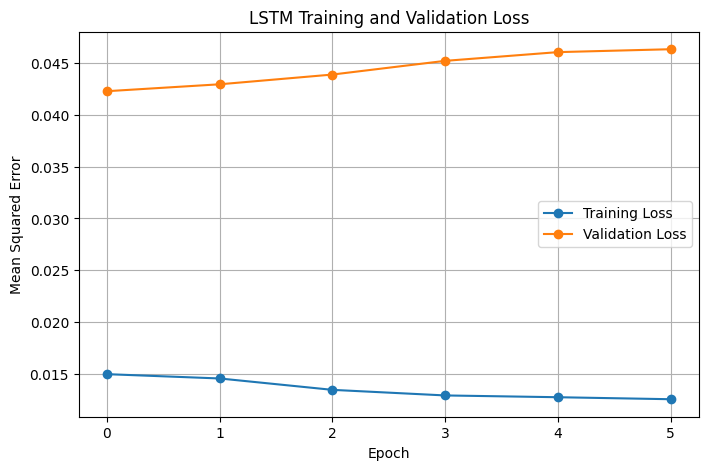

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss", marker="o")
plt.plot(history.history["val_loss"], label="Validation Loss", marker="o")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()


In [12]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict rainfall for the test dataset
pred_scaled = model.predict(X_test, verbose=0)

# Convert scaled values back to original rainfall values
y_test_mm = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

pred_mm = scaler.inverse_transform(
    pred_scaled
).flatten()

# Rainfall cannot be negative
pred_mm = np.maximum(pred_mm, 0)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_mm, pred_mm)
rmse = np.sqrt(mean_squared_error(y_test_mm, pred_mm))

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")


Mean Absolute Error (MAE): 3.1582
Root Mean Squared Error (RMSE): 3.5330


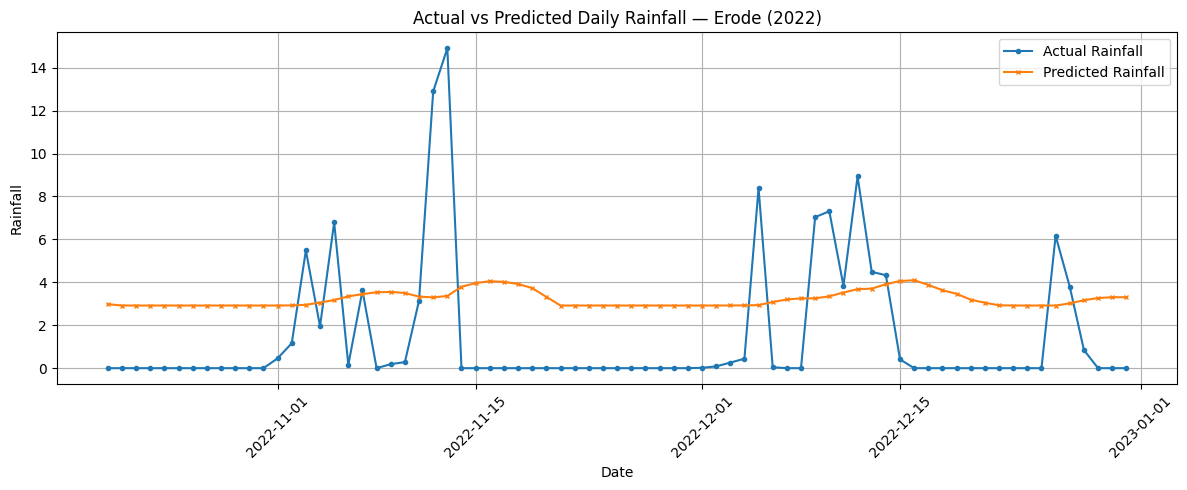

In [13]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    test_dates, y_test_mm,
    label="Actual Rainfall", marker="o", markersize=3
)

plt.plot(
    test_dates, pred_mm,
    label="Predicted Rainfall", marker="x", markersize=3
)

plt.title("Actual vs Predicted Daily Rainfall — Erode (2022)")
plt.xlabel("Date")
plt.ylabel("Rainfall")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Seven-day rainfall forecast:


,Future Date,Predicted Rainfall
0,2023-01-01,3.2733
1,2023-01-02,3.2840
2,2023-01-03,3.1979
3,2023-01-04,3.2091
4,2023-01-05,3.3047
5,2023-01-06,3.4175
6,2023-01-07,3.5217


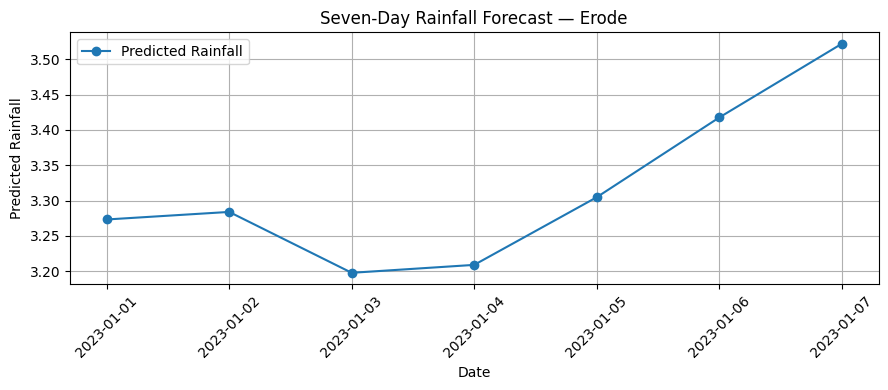

In [14]:

# Step 15: Forecast the next 7 days

last_sequence = scaled_rainfall[-7:].copy()
future_predictions = []

for i in range(7):
    next_scaled = model.predict(
        last_sequence.reshape(1, 7, 1),
        verbose=0
    )[0, 0]

    future_predictions.append(next_scaled)

    # Use the prediction to forecast the next day
    last_sequence = np.concatenate(
        [last_sequence[1:], np.array([[next_scaled]])],
        axis=0
    )

# Convert predictions back to the original scale
future_predictions = scaler.inverse_transform(
    np.array(future_predictions).reshape(-1, 1)
).flatten()

future_predictions = np.maximum(future_predictions, 0)

future_dates = pd.date_range(
    start=daily_df.index[-1] + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

future_results = pd.DataFrame({
    "Future Date": future_dates,
    "Predicted Rainfall": np.round(future_predictions, 4)
})

print("Seven-day rainfall forecast:")
display(future_results)

# Plot future predictions
plt.figure(figsize=(9, 4))
plt.plot(
    future_dates,
    future_predictions,
    marker="o",
    label="Predicted Rainfall"
)
plt.title("Seven-Day Rainfall Forecast — Erode")
plt.xlabel("Date")
plt.ylabel("Predicted Rainfall")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Load the CSV file
file_path = csv_files[0]
df = pd.read_csv(file_path, sep=";")

# Clean column names
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace('"', '', regex=False)
)

# Display dataset information
print("Dataset shape:", df.shape)
print("\nTotal rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum().to_frame(name="Missing Count"))


Dataset shape: (8790, 34)

Total rows: 8790
Total columns: 34

Column names:
['state', 'district', 'month', '1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th', '9th', '10th', '11th', '12th', '13th', '14th', '15th', '16th', '17th', '18th', '19th', '20th', '21st', '22nd', '23rd', '24th', '25th', '26th', '27th', '28th', '29th', '30th', '31st']

First 5 rows:


,state,district,month,1st,2nd,3rd,4th,5th,6th,7th,...,22nd,23rd,24th,25th,26th,27th,28th,29th,30th,31st
0,Andaman & Nicobar,Nicobars,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,Andaman & Nicobar,North And Middle Andaman,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,Andaman & Nicobar,South Andamans,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,Andhra Pradesh,Anantapur,1,0.379965,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.205834,0.671002,0.028994,0.0,0.0,0.0
4,Andhra Pradesh,Chittoor,1,14.144900,0.857263,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.615237,0.925098,0.507623,0.424843,0.737394,0.0,0.0,0.0



Missing values:


,Missing Count
state,0
district,0
month,0
1st,0
2nd,0
3rd,0
4th,0
5th,0
6th,0
7th,0


In [16]:

# Display the dataset as an interactive table
display(df)


,state,district,month,1st,2nd,3rd,4th,5th,6th,7th,...,22nd,23rd,24th,25th,26th,27th,28th,29th,30th,31st
0,Andaman & Nicobar,Nicobars,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,Andaman & Nicobar,North And Middle Andaman,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,Andaman & Nicobar,South Andamans,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,Andhra Pradesh,Anantapur,1,0.379965,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.205834,0.671002,0.028994,0.0,0.0,0.0
4,Andhra Pradesh,Chittoor,1,14.144900,0.857263,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.615237,0.925098,0.507623,0.424843,0.737394,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8785,West Bengal,Murshidabad,12,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.006543,0.485502,0.000000,0.0,0.0,0.0
8786,West Bengal,Nadia,12,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.019657,0.002422,0.0,0.0,0.0
8787,West Bengal,Paschim Bardhaman,12,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000958,0.0,0.000000,0.000000,0.000000,0.319227,0.001392,0.0,0.0,0.0
8788,West Bengal,Purba Bardhaman,12,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.037060,0.000000,0.0,0.0,0.0
